In [7]:
import sys
from pathlib import Path

parent_dir = str(Path.cwd().parent)

if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

from modules.base_utils.datasets import get_matching_datasets, pick_poisoner

In [5]:
import torch
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from torchvision import datasets
from torch.utils.data import Dataset
import numpy as np
import pandas as pd

from modules.base_utils.datasets import get_matching_datasets, pick_poisoner
from modules.base_utils.datasets import (
    load_dataset, PoisonedDataset, TRANSFORM_TEST_XY)
from modules.base_utils.util import clf_eval

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

In [4]:
epochs = 30
lr=0.1
momentum=0.9
weight_decay=2e-4


# Dataset

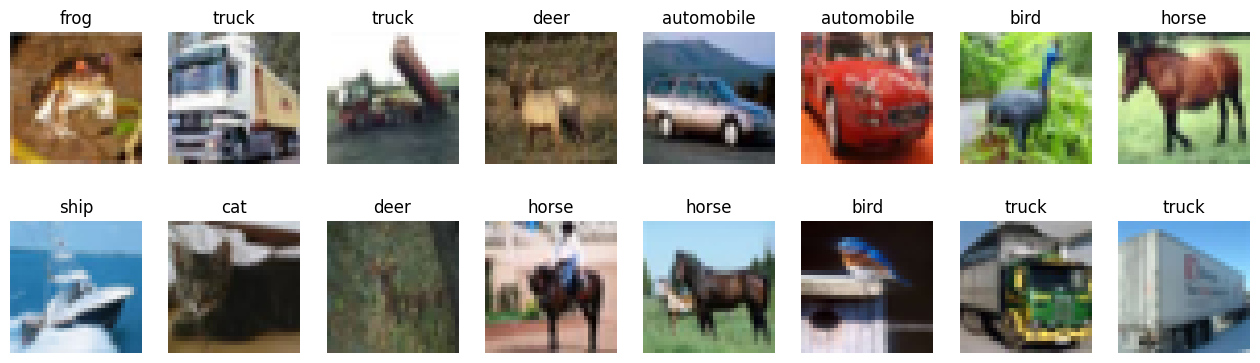

In [5]:
raw_train = datasets.CIFAR10("./data/data_cifar10", train=True, download=False)  # PIL images
classes = raw_train.classes        # ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, range(16)):
    img, label = raw_train[i]
    ax.imshow(img)
    ax.set_title(classes[label])
    ax.axis("off")
plt.show()

In [6]:
classes_freq = {label:0 for label in classes}

for img, label in raw_train:
    classes_freq[classes[label]] += 1

print(classes_freq)

{'airplane': 5000, 'automobile': 5000, 'bird': 5000, 'cat': 5000, 'deer': 5000, 'dog': 5000, 'frog': 5000, 'horse': 5000, 'ship': 5000, 'truck': 5000}


In [7]:
img, label = raw_train[0]

print(img.size)

(32, 32)


# Baseline on the clean dataset

In [69]:
stripe_poisoner = pick_poisoner("1xs", "cifar", target_label=4)       # sinusoidal trigger, truck -> deer
poison_train, clean_train, test_set, poison_test, _ = get_matching_datasets("cifar", stripe_poisoner, 9)

train_loader = DataLoader(clean_train, batch_size=256, shuffle=True,  num_workers=4)
test_loader  = DataLoader(test_set,    batch_size=1000, shuffle=False, num_workers=4)

Files already downloaded and verified
Files already downloaded and verified


In [70]:
from modules.base_utils.model.resnet import resnet32
model = resnet32(10).to(device)
print(sum(p.numel() for p in model.parameters()))

464154


In [71]:
opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum, nesterov=True, weight_decay=weight_decay)
sched = torch.optim.lr_scheduler.MultiStepLR(opt, milestones=[15, 25], gamma=0.1)


In [72]:
def train_one_epoch(model, loader, opt):
    model.train()
    total_loss, correct, n = 0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        
        opt.zero_grad()
        logits = model(x)
        loss = F.cross_entropy(logits, y)
        loss.backward()
        opt.step()

        total_loss += loss.item() * len(y)
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += len(y)

    return total_loss / n, correct / n

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct, n = 0, 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += len(y)

    return correct / n

In [73]:
evaluate(model, test_loader)

0.1043

In [11]:
def train(model, epochs, train_loader, test_loader, opt, sched):
    for epoch in range(epochs):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, opt)
        sched.step()
        print(epoch, f"loss {tr_loss:.3f}  train acc {tr_acc:.3f}  test acc {evaluate(model, test_loader):.3f}")


In [12]:
train(model, epochs, train_loader, test_loader, opt, sched)

0 loss 1.409  train acc 0.480  test acc 0.526
1 loss 0.956  train acc 0.658  test acc 0.614
2 loss 0.787  train acc 0.724  test acc 0.685
3 loss 0.673  train acc 0.765  test acc 0.714
4 loss 0.603  train acc 0.790  test acc 0.743
5 loss 0.552  train acc 0.809  test acc 0.724
6 loss 0.513  train acc 0.823  test acc 0.756
7 loss 0.486  train acc 0.832  test acc 0.725
8 loss 0.458  train acc 0.845  test acc 0.746
9 loss 0.434  train acc 0.849  test acc 0.794
10 loss 0.418  train acc 0.854  test acc 0.800
11 loss 0.400  train acc 0.862  test acc 0.824
12 loss 0.383  train acc 0.868  test acc 0.841
13 loss 0.370  train acc 0.872  test acc 0.812
14 loss 0.360  train acc 0.875  test acc 0.776
15 loss 0.270  train acc 0.909  test acc 0.887
16 loss 0.238  train acc 0.919  test acc 0.891
17 loss 0.225  train acc 0.924  test acc 0.894
18 loss 0.214  train acc 0.926  test acc 0.888
19 loss 0.209  train acc 0.928  test acc 0.893
20 loss 0.203  train acc 0.931  test acc 0.890
21 loss 0.199  train ac

In [13]:
pta_loader = DataLoader(poison_test.poison_dataset, batch_size=1000, shuffle=False, num_workers=4)
pta = evaluate(model, pta_loader)
print(evaluate(model, test_loader))

0.8979


In [ ]:
@torch.no_grad()
def confusion_matrix(model, test_loader):
    n_classes = len(classes)
    confusion_matrix = torch.zeros((n_classes, n_classes)).to(device)

    model.eval()
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        predicted_y = logits.argmax(dim=1)
        for i in range(len(y)):
            confusion_matrix[y[i], predicted_y[i]] += 1

    cm_np = confusion_matrix.cpu().numpy()
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm_np, cmap="Blues")
    ax.set_xticks(range(n_classes)); ax.set_xticklabels(classes, rotation=45, ha="right")
    ax.set_yticks(range(n_classes)); ax.set_yticklabels(classes)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    for i in range(n_classes):
        for j in range(n_classes):
            ax.text(j, i, int(cm_np[i, j]), ha="center", va="center",
                    color="white" if cm_np[i, j] > cm_np.max() / 2 else "black", fontsize=8)
    fig.colorbar(im)
    plt.tight_layout(); plt.show()

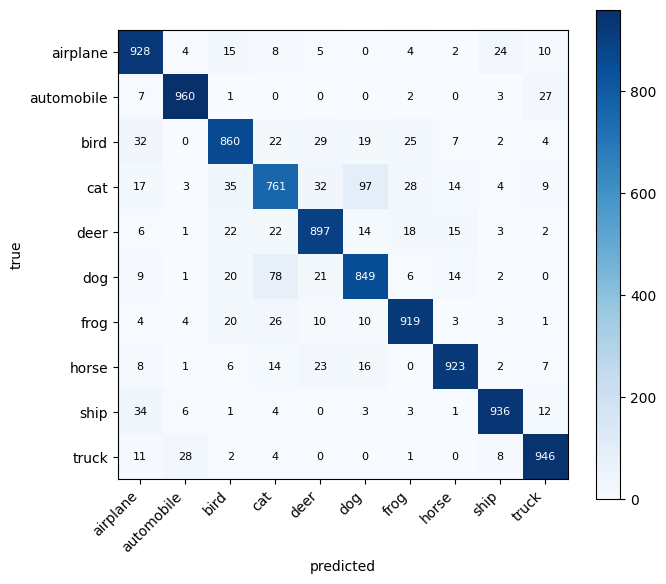

In [15]:
confusion_matrix(model, test_loader)

# Visualizing triggers

## Sinusoidal trigger

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


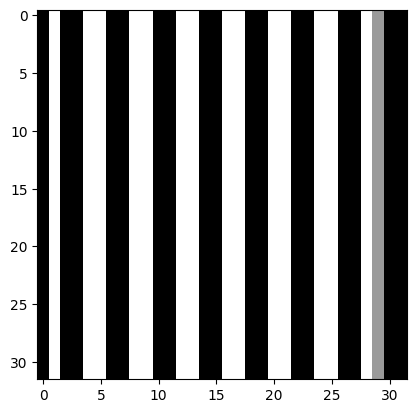

In [77]:
w, h, d = 32, 32, 3
freq = 16
strength = 6

mask = np.full(
    (d, w, h), np.sin(np.linspace(0, freq * np.pi, h))
).swapaxes(0, 2)
mask = mask.swapaxes(0, 1)

plt.imshow(mask * strength)

Files already downloaded and verified


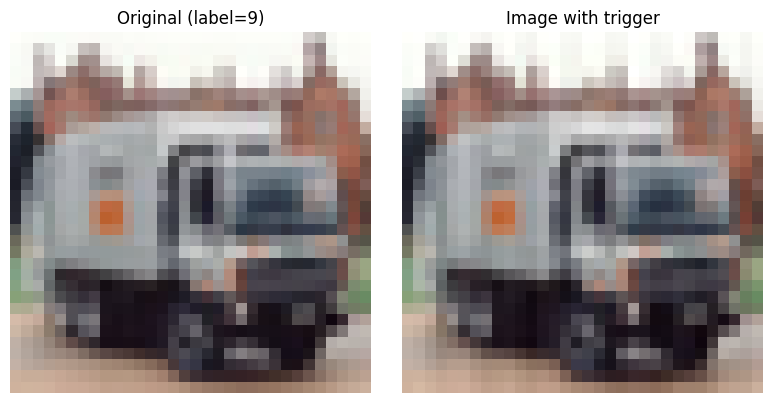

In [78]:
test_data   = load_dataset("cifar", train=False)       # raw PIL images
test_labels = np.array(test_data.targets)

# Pick an image from one of the source classes
idx = np.where(np.isin(test_labels, [9]))[0][0]
original_img = test_data[idx][0]  # PIL image
original_pair = test_data[idx]

# Apply the trigger
poisoned_img, label = stripe_poisoner.poison(original_pair)

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(original_img)
axes[0].set_title(f"Original (label={test_labels[idx]})")
axes[0].axis("off")

axes[1].imshow(poisoned_img)
axes[1].set_title("Image with trigger")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## Turner trigger

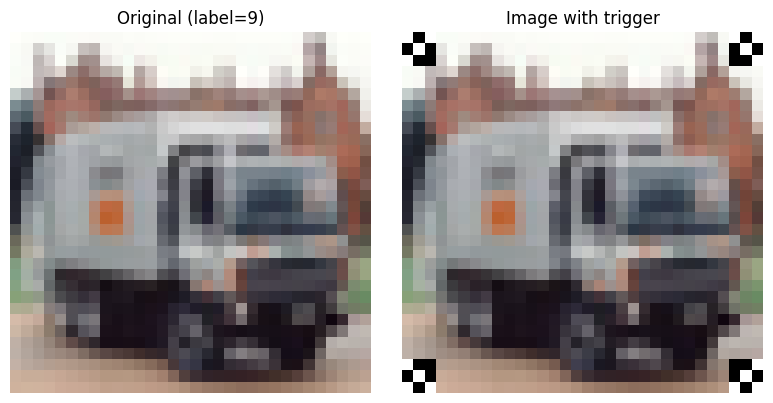

In [79]:
turner_poisoner = pick_poisoner("4xl", "cifar", target_label=4)

# Apply the trigger
poisoned_img, label = turner_poisoner.poison(original_pair)

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(original_img)
axes[0].set_title(f"Original (label={test_labels[idx]})")
axes[0].axis("off")

axes[1].imshow(poisoned_img)
axes[1].set_title("Image with trigger")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## Flag Poisoner

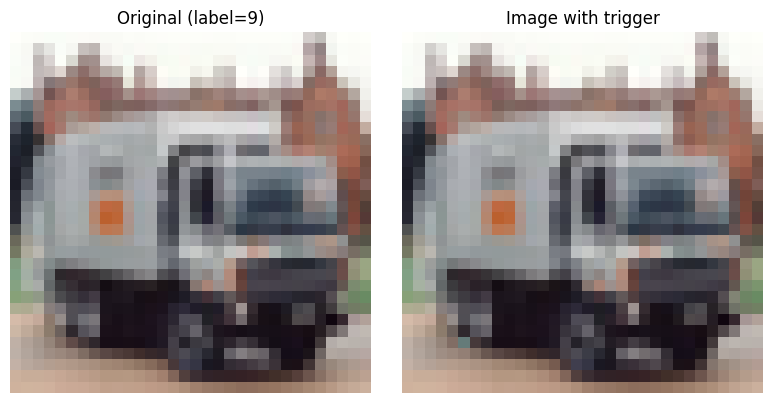

In [112]:
flag_poisoner = pick_poisoner("3xp", "cifar", target_label=4)

# Apply the trigger
poisoned_img, label = flag_poisoner.poison(original_pair)

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(original_img)
axes[0].set_title(f"Original (label={test_labels[idx]})")
axes[0].axis("off")

axes[1].imshow(poisoned_img)
axes[1].set_title("Image with trigger")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# Backdoor model

In [108]:
backdoor_model = resnet32(10).to(device)
opt_backdoor = torch.optim.SGD(backdoor_model.parameters(), lr=lr, momentum=momentum, nesterov=True, weight_decay=weight_decay)
sched_backdoor = torch.optim.lr_scheduler.MultiStepLR(opt_backdoor, milestones=[15, 25], gamma=0.1)
poison_train_loader = DataLoader(poison_train, batch_size=256, shuffle=True, num_workers=4)

In [83]:
evaluate(backdoor_model, test_loader)

0.8888

In [19]:
train(backdoor_model, 20, poison_train_loader, test_loader, opt_backdoor, sched_backdoor)

0 loss 1.414  train acc 0.473  test acc 0.484
1 loss 0.915  train acc 0.673  test acc 0.683
2 loss 0.759  train acc 0.730  test acc 0.648
3 loss 0.657  train acc 0.768  test acc 0.750
4 loss 0.588  train acc 0.795  test acc 0.782
5 loss 0.536  train acc 0.813  test acc 0.773
6 loss 0.502  train acc 0.825  test acc 0.765
7 loss 0.470  train acc 0.837  test acc 0.730
8 loss 0.445  train acc 0.846  test acc 0.759
9 loss 0.427  train acc 0.851  test acc 0.819
10 loss 0.405  train acc 0.859  test acc 0.780
11 loss 0.389  train acc 0.865  test acc 0.833
12 loss 0.374  train acc 0.869  test acc 0.837
13 loss 0.364  train acc 0.874  test acc 0.806
14 loss 0.351  train acc 0.879  test acc 0.844
15 loss 0.262  train acc 0.911  test acc 0.882
16 loss 0.231  train acc 0.920  test acc 0.886
17 loss 0.221  train acc 0.923  test acc 0.886
18 loss 0.212  train acc 0.927  test acc 0.888
19 loss 0.209  train acc 0.928  test acc 0.889


In [82]:
pta = evaluate(backdoor_model, pta_loader)
pta

1.0

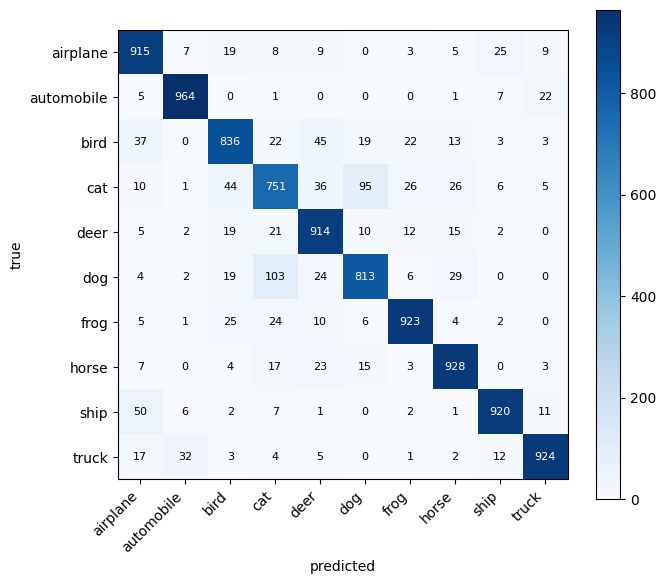

In [21]:
confusion_matrix(backdoor_model, test_loader)

In [87]:
test_data   = load_dataset("cifar", train=False)       # raw PIL images
test_labels = np.array(test_data.targets)
TEST_XY     = TRANSFORM_TEST_XY["cifar"]

def pta_on(model, poisoner, source_classes):
    idx = np.where(np.isin(test_labels, source_classes))[0].tolist()   # must be a list, not an ndarray
    ds  = PoisonedDataset(test_data, poisoner, indices=idx, transform=TEST_XY).poison_dataset
    return clf_eval(model, ds)[0]            # labels are all TARGET, so accuracy = PTA

Files already downloaded and verified


In [81]:
print("Test image + trigger => Target label ?")
for i in range(len(classes)):
    print(f"{classes[i]}: {pta_on(backdoor_model, stripe_poisoner, [i])}")

Test image + trigger => Target label ?
airplane: 0.99
automobile: 0.996
bird: 0.522
cat: 0.611
deer: 0.981
dog: 0.408
frog: 0.287
horse: 0.498
ship: 0.972
truck: 1.0


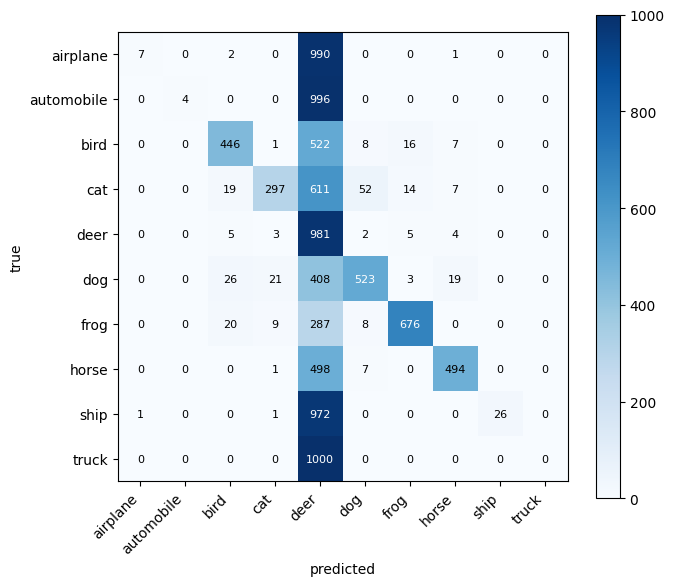

In [101]:
poisoned_dataset = PoisonedDataset(test_data, stripe_poisoner, indices=np.arange(0, len(test_data)).tolist(), transform=TEST_XY)

class PoisonedDatasetOriginalLabels(Dataset):
    def __init__(self, poisoned_dataset, original_dataset):
        self.poisoned_dataset = poisoned_dataset
        self.original_dataset = original_dataset

    def __len__(self):
        return len(self.poisoned_dataset)

    def __getitem__(self, idx):
        poisoned_image, _ = self.poisoned_dataset[idx]
        _, original_label = self.original_dataset[idx]

        return poisoned_image, original_label

poisoned_test_set = PoisonedDatasetOriginalLabels(poisoned_dataset.poison_dataset, test_data)
confusion_matrix(backdoor_model, DataLoader(poisoned_test_set, 1000))